## Problem Statement

### Business Context

Modern organizations operate in an environment where internal policies have grown increasingly complex, covering areas such as leaves, reimbursements, travel, hybrid work norms, performance management, compliance, and more. These policies are commonly documented in static, lengthy HR handbooks or PDFs, which employees often find difficult to understand, search, or apply in their daily work scenarios.

As a result:
- HR teams are burdened with repetitive queries about standard policies, diverting their focus from strategic initiatives.
- Employees struggle with confusion or non-compliance, as the dense and static format of policy documents obscures the necessary guidance.
- Both sides suffer from reduced productivity — HR spends excessive time addressing routine questions, while employees experience delays in obtaining the information they need to perform efficiently.

Addressing these challenges requires modern HR systems that centralize policy information, simplify access, and deliver clear, actionable insights. By leveraging technology to streamline policy communication and automate routine queries, organizations can enhance clarity, boost compliance, and ultimately improve overall operational efficiency.

**Questions to Answer**

**1. Probation Benefits:** "What are the effects on the benefits I receive if my probation is extended?"

**2. Bereavement Leave:** "There has been a demise in my family last night, and I need to attend the last rites. How should I inform the office, and will I be granted leave?"

**3. Harassment Reporting:** "What should I do if I notice suspected harassment with my female colleague?"

### Objective

The goal is to develop a prototype that demonstrates how Natural Language Processing (NLP), powered by Retrieval-Augmented Generation (RAG), can help employees efficiently query company HR policies and receive accurate, context-aware, and easily understandable answers. Specifically, the system aims to:

- Answer employee questions by retrieving relevant content from official HR handbooks and policy documents.
- Handle ambiguous queries and follow-up questions by clarifying intent and distinguishing between similar policy categories.
- Personalize responses based on role, location, or department, acknowledging that policies may differ.
- Increase trust and compliance by citing sources (document name, section, and clause) for each response.

### Data Description

The employee handbook is an internal reference published by **Flykite Airlines** that outlines a wide range of workplace policies, guidelines, and procedures for staff. The handbook is provided in PDF format and serves as a comprehensive resource for employees across different roles within the airline.

## Installing and Importing Necessary Libraries and Dependencies

In [1]:
# Installation for GPU llama-cpp-python
# Uncomment and run the following code in case GPU is being used
# !CMAKE_ARGS="-DLLAMA_CUBLAS=on" FORCE_CMAKE=1 pip install llama-cpp-python==0.1.85 --force-reinstall --no-cache-dir -q

# Installation for CPU llama-cpp-python
# Uncomment and run the following code in case GPU is not being used
# !CMAKE_ARGS="-DLLAMA_CUBLAS=off" FORCE_CMAKE=1 pip install llama-cpp-python==0.1.85 --force-reinstall --no-cache-dir -q
try:
    import llama_cpp
    print("llama-cpp-python already installed.")
except ImportError:
    import subprocess, sys
    subprocess.check_call([
        sys.executable, "-m", "pip", "install",
        "llama-cpp-python==0.1.85", "-q",
    ])

llama-cpp-python already installed.


**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [2]:
# For installing the libraries & downloading models from HF Hub
import importlib.util, subprocess, sys
required = ["pandas", "matplotlib", "langchain_community", "chromadb", "sentence_transformers", "llama_cpp"]
missing = [m for m in required if importlib.util.find_spec(m) is None]
if missing:
    print("Installing missing packages:", missing)
    subprocess.check_call([
        sys.executable, "-m", "pip", "install",
        "huggingface_hub==0.35.3", "pandas==2.2.2", "tiktoken==0.12.0", "pymupdf==1.26.5",
        "langchain==0.3.27", "langchain-community==0.3.31", "langchain-text-splitters==0.3.11",
        "chromadb==1.1.1", "sentence-transformers==5.1.1", "numpy==2.3.3", "-q",
    ])
else:
    print("Core dependencies already available in this environment.")

Core dependencies already available in this environment.


**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.

In [3]:
# Libraries for processing dataframes and text
import json, os
import pandas as pd

# Libraries for Loading Data, Chunking, Embedding, and Vector Databases
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyMuPDFLoader
from langchain_community.embeddings.sentence_transformer import SentenceTransformerEmbeddings
from langchain_community.vectorstores import Chroma

# Libraries for downloading and loading the LLM
from huggingface_hub import hf_hub_download
from llama_cpp import Llama

/Users/preetikujur/Downloads/test/CAPSTONE_PROJECT2026/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/var/folders/v7/9cvyn3n91k37kxmr8t66bw600000gn/T/ipykernel_3292/1818389649.py:7: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyMuPDFLoader


## Question Answering using LLM

#### Downloading and Loading the model

In [4]:
# Download the Mistral-7B-Instruct model from Hugging Face Hub
model_name = "TheBloke/Mistral-7B-Instruct-v0.1-GGUF"
model_file = "mistral-7b-instruct-v0.1.Q4_K_M.gguf"

cached_model = os.environ.get("LLM_GGUF_PATH")
if cached_model and os.path.exists(cached_model):
    model_path = cached_model
    print(f"Using cached model: {model_path}")
else:
    model_path = hf_hub_download(
        repo_id=model_name,
        filename=model_file,
        repo_type="model"
    )
    print(f"Model downloaded at: {model_path}")

# Load the model using llama-cpp-python
llm = Llama(
    model_path=model_path,
    n_ctx=4096,       # Context window
    n_threads=8,      # Number of CPU threads to use
    n_gpu_layers=0    # Set to 35 for GPU; 0 for CPU only
)

print("Model loaded successfully!")

ggml_metal_device_init: tensor API disabled for pre-M5 and pre-A19 devices


ggml_metal_library_init: using embedded metal library


ggml_metal_library_init: loaded in 0.028 sec


ggml_metal_rsets_init: creating a residency set collection (keep_alive = 180 s)


ggml_metal_device_init: GPU name:   MTL0 (Apple M4)


...

sched_reserve: graph nodes  = 1158


sched_reserve: graph splits = 65 (with bs=512), 1 (with bs=1)


sched_reserve: reserve took 6.29 ms, sched copies = 1


Model loaded successfully!


MTL : EMBED_LIBRARY = 1 | CPU : NEON = 1 | ARM_FMA = 1 | FP16_VA = 1 | MATMUL_INT8 = 1 | DOTPROD = 1 | SME = 1 | SME2 = 1 | ACCELERATE = 1 | REPACK = 1 | 
Model metadata: {'general.quantization_version': '2', 'tokenizer.ggml.unknown_token_id': '0', 'tokenizer.ggml.eos_token_id': '2', 'tokenizer.ggml.bos_token_id': '1', 'tokenizer.ggml.model': 'llama', 'llama.attention.head_count_kv': '8', 'llama.context_length': '32768', 'llama.attention.head_count': '32', 'llama.rope.freq_base': '10000.000000', 'llama.rope.dimension_count': '128', 'general.file_type': '15', 'llama.feed_forward_length': '14336', 'llama.embedding_length': '4096', 'llama.block_count': '32', 'general.architecture': 'llama', 'llama.attention.layer_norm_rms_epsilon': '0.000010', 'general.name': 'mistralai_mistral-7b-instruct-v0.1'}
Using fallback chat format: llama-2


#### Response Generation Function

In [5]:
def response(query, max_tokens=128, temperature=0, top_p=0.95, top_k=50):
    """Generate a response from the LLM with configurable parameters."""
    model_output = llm(
        prompt=query,
        max_tokens=max_tokens,
        temperature=temperature,
        top_p=top_p,
        top_k=top_k
    )
    return model_output['choices'][0]['text']

#### Evaluation Framework — Groundedness and Relevance

In [6]:
groundedness_rater_system_message = """You are an expert evaluator assessing the groundedness of AI-generated answers.

Groundedness measures whether the answer is fully supported by and derived from the provided context.

Provide a score from 1-5:
5 - Completely grounded: All information directly from context, no unsupported claims
4 - Mostly grounded: Minor unsupported details but core information is from context
3 - Partially grounded: Some information from context, some from external knowledge
2 - Minimally grounded: Mostly external information, little from context
1 - Not grounded: Answer ignores context or contradicts it

Respond with the score and a brief justification."""

relevance_rater_system_message = """You are an expert evaluator assessing the relevance of AI-generated answers to user questions.

Relevance measures how well the answer addresses the specific question asked.

Provide a score from 1-5:
5 - Highly relevant: Directly and completely addresses all aspects of the question
4 - Mostly relevant: Addresses main aspects with minor gaps or tangents
3 - Moderately relevant: Addresses some aspects but misses key points
2 - Minimally relevant: Tangentially related but doesn't address core question
1 - Not relevant: Answer doesn't address the question

Respond with the score and a brief justification."""

def evaluate_response(question, answer, context="No context provided (baseline LLM)."):
    """Evaluate groundedness and relevance using LLM-as-a-judge."""
    eval_prompt = f"""[INST]{groundedness_rater_system_message}

Context: {context}
Question: {question}
Answer: {answer}
Please evaluate the above answer.[/INST]"""
    groundedness_eval = response(eval_prompt, max_tokens=128, temperature=0)

    eval_prompt = f"""[INST]{relevance_rater_system_message}

Question: {question}
Answer: {answer}
Please evaluate the above answer.[/INST]"""
    relevance_eval = response(eval_prompt, max_tokens=128, temperature=0)
    return groundedness_eval, relevance_eval

### Query 1: What are the effects on the benefits I receive if my probation is extended?

In [7]:
query1 = "What are the effects on the benefits I receive if my probation is extended?"

response_q1 = response(query1, max_tokens=256, temperature=0, top_p=0.95, top_k=50)
print("Response:")
print(response_q1)
print("\n" + "="*80 + "\n")

groundedness_q1, relevance_q1 = evaluate_response(query1, response_q1)
print("Groundedness Evaluation:")
print(groundedness_q1)
print("\nRelevance Evaluation:")
print(relevance_q1)
print("\n" + "="*80 + "\n")

print("Comments/Observations:")
print("""
- The LLM response without access to the Flykite HR Handbook shows generic HR knowledge
- The answer may lack specific Flykite policy details (e.g., PIP requirements, 90-day extension limit)
- Temperature=0 ensures deterministic output for policy-related information
- Without RAG, the model relies solely on pre-training knowledge which may not reflect company-specific rules
- The response may contain hallucinations or incomplete information about probation benefit restrictions
- Groundedness is expected to be low (1-2) as no handbook context is provided
""")

llama_perf_context_print:        load time =    1174.95 ms


llama_perf_context_print: prompt eval time =    1169.46 ms /    17 tokens (   68.79 ms per token,    14.54 tokens per second)


llama_perf_context_print:        eval time =   12339.78 ms /   255 runs   (   48.39 ms per token,    20.66 tokens per second)


llama_perf_context_print:       total time =   13552.23 ms /   272 tokens


llama_perf_context_print:    graphs reused =        253


...

llama_perf_context_print: prompt eval time =    5716.76 ms /   426 tokens (   13.42 ms per token,    74.52 tokens per second)


llama_perf_context_print:        eval time =    5652.83 ms /   114 runs   (   49.59 ms per token,    20.17 tokens per second)


llama_perf_context_print:       total time =   11380.58 ms /   540 tokens


llama_perf_context_print:    graphs reused =        112


Groundedness Evaluation:
 Score: 4 - Mostly grounded.

Justification: The answer provides several possible outcomes of an extension of probation on benefits, and each outcome is supported by specific rules or regulations regarding probation and benefits. However, some details such as the specific rules for each state regarding unemployment benefits and the reduction in SSI benefits for an extension of probation are not explicitly stated in the context and may require additional research.

Relevance Evaluation:
 Score: 4 - Mostly relevant

The answer provides a comprehensive overview of the potential effects of an extended probation on various types of benefits, including unemployment, Social Security, Medicaid, and food stamps. It addresses the main aspects of the question and provides specific information for each type of benefit. However, there may be some minor gaps or tangents in the explanation, such as the mention of Supplemental Security Income (SSI) without further elaboration.

### Query 2: There has been a demise in my family last night, and I need to attend the last rites. How should I inform the office, and will I be granted leave?

In [8]:
query2 = ("There has been a demise in my family last night, and I need to attend the last rites. "
          "How should I inform the office, and will I be granted leave?")

response_q2 = response(query2, max_tokens=256, temperature=0, top_p=0.95, top_k=50)
print("Response:")
print(response_q2)
print("\n" + "="*80 + "\n")

groundedness_q2, relevance_q2 = evaluate_response(query2, response_q2)
print("Groundedness Evaluation:")
print(groundedness_q2)
print("\nRelevance Evaluation:")
print(relevance_q2)
print("\n" + "="*80 + "\n")

print("Comments/Observations:")
print("""
- LLM provides general bereavement leave guidance but may miss Flykite-specific notification timelines
- The 6-hour verbal / 24-hour written notification requirement may not be mentioned
- Probation-specific bereavement limits (max 2 consecutive days) are likely absent
- Response may be empathetic but lack authoritative source grounding
- Relevance may be moderate as both notification and leave entitlement are partially addressed
""")

Llama.generate: 1 prefix-match hit, remaining 36 prompt tokens to eval


llama_perf_context_print:        load time =    1174.95 ms


llama_perf_context_print: prompt eval time =     493.38 ms /    36 tokens (   13.71 ms per token,    72.97 tokens per second)


llama_perf_context_print:        eval time =   11133.60 ms /   232 runs   (   47.99 ms per token,    20.84 tokens per second)


llama_perf_context_print:       total time =   11659.28 ms /   268 tokens


...

llama_perf_context_print: prompt eval time =    5698.88 ms /   422 tokens (   13.50 ms per token,    74.05 tokens per second)


llama_perf_context_print:        eval time =    6277.60 ms /   127 runs   (   49.43 ms per token,    20.23 tokens per second)


llama_perf_context_print:       total time =   11990.14 ms /   549 tokens


llama_perf_context_print:    graphs reused =        125


Groundedness Evaluation:
 Score: 4 - Mostly grounded.

The answer is mostly grounded as it provides relevant information about informing the office and taking leave in case of a family emergency or bereavement. The answer also acknowledges the difficulty of losing a loved one and provides guidance on how to communicate with the supervisor or HR representative. However, the answer is not completely grounded as it does not provide specific information about the company's leave policies or the employee's job position. The answer also does not mention the specifics of the demise in the family, which could have been included for more context.

Relevance Evaluation:
 Score: 4 - Mostly relevant

The AI-generated answer provides relevant information about informing the office and taking leave in case of a family emergency or bereavement. It advises the employee to communicate with their supervisor or HR representative as soon as possible, which is a crucial step in such situations. The answer 

### Query 3: What should I do if I notice suspected harassment with my female colleague?

In [9]:
query3 = "What should I do if I notice suspected harassment with my female colleague?"

response_q3 = response(query3, max_tokens=256, temperature=0, top_p=0.95, top_k=50)
print("Response:")
print(response_q3)
print("\n" + "="*80 + "\n")

groundedness_q3, relevance_q3 = evaluate_response(query3, response_q3)
print("Groundedness Evaluation:")
print(groundedness_q3)
print("\nRelevance Evaluation:")
print(relevance_q3)
print("\n" + "="*80 + "\n")

print("Comments/Observations:")
print("""
- LLM provides generic harassment reporting advice without Flykite-specific channels
- The HR Helpline (+91-8000-456-789) and hr.ethics@flykiteair.com are unlikely to be cited
- Investigation timelines (3-day preliminary, 30-day formal) may be missing
- Anti-retaliation protections specific to Flykite policy may not be included
- Without RAG, employees cannot trust the response for compliance purposes
""")

Llama.generate: 1 prefix-match hit, remaining 16 prompt tokens to eval


llama_perf_context_print:        load time =    1174.95 ms


llama_perf_context_print: prompt eval time =     286.55 ms /    16 tokens (   17.91 ms per token,    55.84 tokens per second)


llama_perf_context_print:        eval time =   11197.78 ms /   237 runs   (   47.25 ms per token,    21.16 tokens per second)


llama_perf_context_print:       total time =   11517.22 ms /   253 tokens


...

llama_perf_context_print: prompt eval time =    5539.03 ms /   407 tokens (   13.61 ms per token,    73.48 tokens per second)


llama_perf_context_print:        eval time =    5960.63 ms /   111 runs   (   53.70 ms per token,    18.62 tokens per second)


llama_perf_context_print:       total time =   11510.63 ms /   518 tokens


llama_perf_context_print:    graphs reused =        109


Groundedness Evaluation:
 Score: 5 - Completely grounded

The answer is fully supported by and derived from the provided context. It provides specific steps to take in response to suspected harassment, and each step is grounded in the context of the situation. The answer also emphasizes the importance of taking any suspected harassment seriously and taking action to protect oneself and one's colleague, which is also relevant to the context. Overall, the answer is completely grounded in the provided context.

Relevance Evaluation:
 Score: 5

The answer is highly relevant as it directly and completely addresses all aspects of the question about what to do if you notice suspected harassment with your female colleague. It provides clear and practical steps to take, including listening actively, asking for clarification, documenting the incident, reporting the incident, following up, and being supportive. The answer also emphasizes the importance of taking any suspected harassment seriously

## Question Answering using LLM with Prompt Engineering

### Query 1: What are the effects on the benefits I receive if my probation is extended?

In [10]:
query1 = "What are the effects on the benefits I receive if my probation is extended?"

print("="*80)
print("COMBINATION 1: Zero-shot with HR Policy Expert Role")
print("="*80)
prompt1 = f"""You are an experienced HR policy specialist at Flykite Airlines. {query1}
Provide a detailed explanation of benefit impacts during probation extension."""
resp1 = response(prompt1, max_tokens=300, temperature=0, top_p=0.95, top_k=50)
print(resp1)
print("\nObservation: Role-based context guides the model toward structured HR policy responses.\n")

print("="*80)
print("COMBINATION 2: Structured Output Format")
print("="*80)
prompt2 = f"""As a Flykite Airlines HR assistant, answer the following in this format:
- Benefit Restrictions:
- Seniority Impact:
- Extension Conditions:
- Recommended Actions:

Question: {query1}"""
resp2 = response(prompt2, max_tokens=350, temperature=0.1, top_p=0.95, top_k=50)
print(resp2)
print("\nObservation: Explicit formatting creates organized, scannable responses for employees.\n")

print("="*80)
print("COMBINATION 3: Chain-of-Thought Reasoning")
print("="*80)
prompt3 = f"""{query1}
Let's think step by step about how probation extension affects employee benefits at an airline company."""
resp3 = response(prompt3, max_tokens=350, temperature=0.3, top_p=0.9, top_k=40)
print(resp3)
print("\nObservation: CoT prompting encourages logical progression through benefit categories.\n")

groundedness_pe1, relevance_pe1 = evaluate_response(query1, resp2)
print("="*80)
print("EVALUATION (Best Prompt — Structured Output):")
print("="*80)
print("Groundedness:", groundedness_pe1)
print("Relevance:", relevance_pe1)
print("\nKEY OBSERVATIONS:")
print("""
1. Role-based prompts improve domain-specific tone and structure
2. Structured output format enhances readability for employees
3. Prompt engineering improves relevance but groundedness remains limited without RAG
4. Temperature=0.0-0.1 recommended for policy accuracy
""")

Llama.generate: 1 prefix-match hit, remaining 43 prompt tokens to eval


COMBINATION 1: Zero-shot with HR Policy Expert Role


llama_perf_context_print:        load time =    1174.95 ms


llama_perf_context_print: prompt eval time =     629.22 ms /    43 tokens (   14.63 ms per token,    68.34 tokens per second)


llama_perf_context_print:        eval time =   14208.78 ms /   299 runs   (   47.52 ms per token,    21.04 tokens per second)


...

llama_perf_context_print: prompt eval time =    5816.22 ms /   433 tokens (   13.43 ms per token,    74.45 tokens per second)


llama_perf_context_print:        eval time =    5000.34 ms /   102 runs   (   49.02 ms per token,    20.40 tokens per second)


llama_perf_context_print:       total time =   10825.96 ms /   535 tokens


llama_perf_context_print:    graphs reused =        100


EVALUATION (Best Prompt — Structured Output):
Groundedness:  Score: 4 - Mostly grounded.

The answer provides some information that is directly from the context, such as the potential restrictions on benefits during probation and the impact on seniority. However, there are also some minor unsupported details, such as the recommendation to speak with an HR representative. Overall, the core information is from the context, but there are some minor details that are not fully supported.
Relevance:  Score: 4 - Mostly relevant

The answer provides information on some of the effects of extending probation on benefits, such as benefit restrictions and potential impact on seniority. However, it misses key points such as the specific conditions for extending probation and the potential impact on other types of benefits or promotions. Additionally, while the answer recommends speaking with HR and reviewing the employee handbook, it does not provide a comprehensive overview of the potential effect

### Query 2: There has been a demise in my family last night, and I need to attend the last rites. How should I inform the office, and will I be granted leave?

In [11]:
query2 = ("There has been a demise in my family last night, and I need to attend the last rites. "
          "How should I inform the office, and will I be granted leave?")

print("="*80)
print("COMBINATION 1: Empathetic HR Assistant with Action Steps")
print("="*80)
prompt1 = f"""You are a compassionate HR assistant at Flykite Airlines. An employee asks:
{query2}
Provide clear steps for notification and explain leave entitlement."""
resp1 = response(prompt1, max_tokens=350, temperature=0, top_p=0.95, top_k=50)
print(resp1)
print("\nObservation: Empathetic tone with action steps improves employee experience.\n")

print("="*80)
print("COMBINATION 2: Two-Part Structured Response")
print("="*80)
prompt2 = f"""Answer this employee question in two sections:
Section A - How to Inform the Office (Emergency Protocol):
Section B - Leave Entitlement and Documentation:

Question: {query2}"""
resp2 = response(prompt2, max_tokens=400, temperature=0.1, top_p=0.95, top_k=50)
print(resp2)
print("\nObservation: Two-part structure directly addresses both aspects of the multi-part question.\n")

groundedness_pe2, relevance_pe2 = evaluate_response(query2, resp2)
print("EVALUATION (Best Prompt — Two-Part Structure):")
print("Groundedness:", groundedness_pe2)
print("Relevance:", relevance_pe2)
print("\nKEY OBSERVATIONS:")
print("""
1. Multi-part questions benefit from explicit section-based prompts
2. Emergency scenarios require clear notification timelines in the response
3. Relevance improves significantly with structured prompts
4. Flykite-specific bereavement rules still require RAG for full groundedness
""")

Llama.generate: 1 prefix-match hit, remaining 68 prompt tokens to eval


COMBINATION 1: Empathetic HR Assistant with Action Steps


llama_perf_context_print:        load time =    1174.95 ms


llama_perf_context_print: prompt eval time =     924.05 ms /    68 tokens (   13.59 ms per token,    73.59 tokens per second)


llama_perf_context_print:        eval time =   13262.60 ms /   261 runs   (   50.81 ms per token,    19.68 tokens per second)


...

llama_perf_context_print: prompt eval time =    8236.54 ms /   587 tokens (   14.03 ms per token,    71.27 tokens per second)


llama_perf_context_print:        eval time =    6281.71 ms /   127 runs   (   49.46 ms per token,    20.22 tokens per second)


llama_perf_context_print:       total time =   14531.13 ms /   714 tokens


llama_perf_context_print:    graphs reused =        126


EVALUATION (Best Prompt — Two-Part Structure):
Groundedness:  Score: 4 - Mostly grounded.

The answer is mostly grounded as it provides specific instructions on how to inform the office and request leave, as well as the necessary documentation required. However, it lacks some context on the company's leave policy and the number of days off entitled to the employee. Additionally, it does not provide any information on the relationship between the employee and the deceased, which may affect the leave entitlement.
Relevance:  Score: 4 - Mostly relevant

The AI-generated answer provides a comprehensive guide on how to inform the office about a family demise and how to request leave for attending the last rites. It covers the essential steps that the user needs to take, including contacting the supervisor or HR representative, providing necessary documentation, and updating the company records upon return to work. However, the answer could be improved by providing more specific information 

### Query 3: What should I do if I notice suspected harassment with my female colleague?

In [12]:
query3 = "What should I do if I notice suspected harassment with my female colleague?"

print("="*80)
print("COMBINATION 1: HR Compliance Officer Role")
print("="*80)
prompt1 = f"""You are an HR Compliance Officer at Flykite Airlines. {query3}
Provide immediate action steps and reporting procedures."""
resp1 = response(prompt1, max_tokens=350, temperature=0, top_p=0.95, top_k=50)
print(resp1)
print("\nObservation: Compliance-focused persona emphasizes reporting channels and timelines.\n")

print("="*80)
print("COMBINATION 2: Step-by-Step Action Plan with Source Citation")
print("="*80)
prompt2 = f"""As a Flykite Airlines HR policy assistant, provide a step-by-step action plan:
1. Immediate Actions
2. Reporting Channels
3. Investigation Timeline
4. Protection Against Retaliation
5. Source Reference (handbook section)

Question: {query3}"""
resp2 = response(prompt2, max_tokens=400, temperature=0.1, top_p=0.95, top_k=50)
print(resp2)
print("\nObservation: Step-by-step format with source citation request improves actionability.\n")

groundedness_pe3, relevance_pe3 = evaluate_response(query3, resp2)
print("EVALUATION (Best Prompt — Step-by-Step Action Plan):")
print("Groundedness:", groundedness_pe3)
print("Relevance:", relevance_pe3)
print("\nSUMMARY OF PROMPT ENGINEERING OBSERVATIONS:")
print("""
1. Role-based prompts (HR expert persona) improve domain-specific responses
2. Structured output formats create organized, employee-friendly answers
3. Multi-part questions need explicit section-based prompt design
4. Source citation requests prepare the system for RAG integration
5. Temperature tuning: 0.0-0.1 (precise), 0.3 (balanced), 0.5+ (creative but riskier)
6. Prompt engineering significantly improves relevance but groundedness requires RAG
""")

Llama.generate: 1 prefix-match hit, remaining 40 prompt tokens to eval


COMBINATION 1: HR Compliance Officer Role


llama_perf_context_print:        load time =    1174.95 ms


llama_perf_context_print: prompt eval time =     551.89 ms /    40 tokens (   13.80 ms per token,    72.48 tokens per second)


llama_perf_context_print:        eval time =    9164.67 ms /   197 runs   (   46.52 ms per token,    21.50 tokens per second)


...

llama_perf_context_print: prompt eval time =    6449.75 ms /   457 tokens (   14.11 ms per token,    70.86 tokens per second)


llama_perf_context_print:        eval time =    6359.70 ms /   107 runs   (   59.44 ms per token,    16.82 tokens per second)


llama_perf_context_print:       total time =   12821.82 ms /   564 tokens


llama_perf_context_print:    graphs reused =        105


EVALUATION (Best Prompt — Step-by-Step Action Plan):
Groundedness:  Score: 5 - Completely grounded.

The answer is fully supported by and derived from the provided context. All information in the answer is directly from the context, and there are no unsupported claims. The answer provides clear and concise instructions on what to do if you notice suspected harassment with your female colleague, including immediate actions, reporting channels, investigation timeline, protection against retaliation, and source reference. Overall, the answer is well-grounded and provides valuable information to the user.
Relevance:  Score: 5 - Highly relevant

The AI-generated answer provides a comprehensive and direct response to the question about what to do if you notice suspected harassment with your female colleague. It covers all aspects of the question, including immediate actions, reporting channels, investigation timeline, protection against retaliation, and source reference. The answer is clear,

## Data Preparation for RAG

### Loading the Data

In [13]:
# Load the Flykite Airlines HR Policy Handbook PDF
pdf_path = "Dataset - Flykite Airlines_ HRP.pdf"

loader = PyMuPDFLoader(pdf_path)
documents = loader.load()

print(f"Successfully loaded {len(documents)} pages from the Flykite HR Handbook")
print(f"Document type: {type(documents)}")
print(f"First document type: {type(documents[0])}")

Successfully loaded 14 pages from the Flykite HR Handbook
Document type: <class 'list'>
First document type: <class 'langchain_core.documents.base.Document'>


### Data Overview

#### Checking the first 5 pages

In [14]:
# Display first 5 pages content
for i in range(min(5, len(documents))):
    print(f"\n{'='*80}")
    print(f"PAGE {i+1}")
    print(f"{'='*80}")
    print(f"Page Content Length: {len(documents[i].page_content)} characters")
    print(f"\nFirst 500 characters:")
    print(documents[i].page_content[:500])
    print(f"\nMetadata: {documents[i].metadata}")


PAGE 1
Page Content Length: 1422 characters

First 500 characters:
Flykite Airlines: Human Resources Policy 
Handbook 
Introduction 
Flykite Airlines is dedicated to cultivating an organizational culture that synergizes 
operational excellence with a supportive, equitable, and legally compliant workplace 
environment across all departments and employee levels. This document establishes 
an exhaustive framework comprising all human resource policies currently in effect. All 
provisions are subject to amendment, interpretation, or rescindment at the sole 
discret

Metadata: {'producer': 'pdf-lib (https://github.com/Hopding/pdf-lib)', 'creator': 'pdf-lib (https://github.com/Hopding/pdf-lib)', 'creationdate': '2026-08-29T17:06:17+00:00', 'source': 'Dataset - Flykite Airlines_ HRP.pdf', 'file_path': 'Dataset - Flykite Airlines_ HRP.pdf', 'total_pages': 14, 'format': 'PDF 1.7', 'title': 'Flykite Airlines: HRP', 'author': '', 'subject': '', 'keywords': '', 'moddate': '2026-08-29T17:06:17+00:

#### Checking the number of pages

In [15]:
total_pages = len(documents)
print(f"Total number of pages in the Flykite HR Handbook: {total_pages}")

total_chars = sum(len(doc.page_content) for doc in documents)
print(f"Total characters across all pages: {total_chars:,}")
print(f"Average characters per page: {total_chars/total_pages:.2f}")

Total number of pages in the Flykite HR Handbook: 14
Total characters across all pages: 16,273
Average characters per page: 1162.36


### Data Chunking

In [16]:
# Split documents into chunks using RecursiveCharacterTextSplitter
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,          # Size of each chunk in characters
    chunk_overlap=50,        # Overlap between chunks to maintain context
    length_function=len,     # Function to measure chunk length
    separators=["\n\n", "\n", ". ", " ", ""]  # Priority order for splitting
)

chunks = text_splitter.split_documents(documents)

print(f"Total number of chunks created: {len(chunks)}")
print(f"Original pages: {len(documents)}")
print(f"Chunks per page (average): {len(chunks)/len(documents):.2f}")

chunk_lengths = [len(c.page_content) for c in chunks]
print(f"Average chunk length: {sum(chunk_lengths)/len(chunk_lengths):.2f} characters")
print(f"Min chunk length: {min(chunk_lengths)} characters")
print(f"Max chunk length: {max(chunk_lengths)} characters")

print("\n" + "="*80)
print("SAMPLE CHUNK 1:")
print("="*80)
print(chunks[0].page_content[:300])
print(f"\nChunk metadata: {chunks[0].metadata}")

Total number of chunks created: 41
Original pages: 14
Chunks per page (average): 2.93
Average chunk length: 404.71 characters
Min chunk length: 78 characters
Max chunk length: 499 characters

SAMPLE CHUNK 1:
Flykite Airlines: Human Resources Policy 
Handbook 
Introduction 
Flykite Airlines is dedicated to cultivating an organizational culture that synergizes 
operational excellence with a supportive, equitable, and legally compliant workplace 
environment across all departments and employee levels. This

Chunk metadata: {'producer': 'pdf-lib (https://github.com/Hopding/pdf-lib)', 'creator': 'pdf-lib (https://github.com/Hopding/pdf-lib)', 'creationdate': '2026-08-29T17:06:17+00:00', 'source': 'Dataset - Flykite Airlines_ HRP.pdf', 'file_path': 'Dataset - Flykite Airlines_ HRP.pdf', 'total_pages': 14, 'format': 'PDF 1.7', 'title': 'Flykite Airlines: HRP', 'author': '', 'subject': '', 'keywords': '', 'moddate': '2026-08-29T17:06:17+00:00', 'trapped': '', 'modDate': 'D:20260829170617Z', 'c

### Embedding

In [17]:
# Create embedding function using SentenceTransformers
embedding_function = SentenceTransformerEmbeddings(
    model_name="all-MiniLM-L6-v2"  # Fast and efficient model for semantic search
)

print("Embedding model loaded successfully!")
print(f"Model name: all-MiniLM-L6-v2")

# Test the embedding function
sample_text = "What are the effects of probation extension on benefits?"
sample_embedding = embedding_function.embed_query(sample_text)

print(f"\nSample embedding dimensions: {len(sample_embedding)}")
print(f"First 10 values of sample embedding: {sample_embedding[:10]}")

/var/folders/v7/9cvyn3n91k37kxmr8t66bw600000gn/T/ipykernel_3292/1383622063.py:2: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the `langchain-huggingface package and should be used instead. To use it run `pip install -U `langchain-huggingface` and import as `from `langchain_huggingface import HuggingFaceEmbeddings``.
  embedding_function = SentenceTransformerEmbeddings(



Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7571.34it/s]

Embedding model loaded successfully!
Model name: all-MiniLM-L6-v2



Sample embedding dimensions: 384
First 10 values of sample embedding: [-0.03156481310725212, 0.07273604720830917, 0.029953332617878914, -0.010828652419149876, 0.06276289373636246, 0.11129310727119446, 0.016868265345692635, 0.027712173759937286, -0.04325706884264946, -0.026909958571195602]


### Vector Database

In [18]:
# Create Chroma vector database from chunks
vectordb = Chroma.from_documents(
    documents=chunks,
    embedding=embedding_function,
    persist_directory="./chroma_db",
    collection_name="flykite_hr_policies"
)

print("Vector database created successfully!")
print(f"Collection name: flykite_hr_policies")
print(f"Number of documents in database: {vectordb._collection.count()}")

# Test similarity search
test_query = "probation extension benefits"
test_results = vectordb.similarity_search(test_query, k=3)

print(f"\nTest similarity search for: '{test_query}'")
print(f"Number of results: {len(test_results)}")
print("\nFirst result preview:")
print(test_results[0].page_content[:200])

Vector database created successfully!
Collection name: flykite_hr_policies
Number of documents in database: 123

Test similarity search for: 'probation extension benefits'
Number of results: 3

First result preview:
●​ Extensions are granted only if:​
 a. The employee has achieved at least 60% of their probationary objectives.​
 b. A written PIP with measurable targets is issued within 5 working days of the 
orig


### Retriever

In [19]:
# Create retriever from vector database
retriever = vectordb.as_retriever(
    search_type="similarity",  # Use similarity search
    search_kwargs={"k": 3}     # Retrieve top 3 most relevant chunks
)

print("Retriever created successfully!")
print(f"Search type: similarity")
print(f"Default k (number of chunks to retrieve): 3")

Retriever created successfully!
Search type: similarity
Default k (number of chunks to retrieve): 3


#### Testing the Retriever with Project Questions

In [20]:
# Test retriever with all three project questions
project_queries = [
    "What are the effects on the benefits I receive if my probation is extended?",
    "There has been a demise in my family last night, and I need to attend the last rites. "
    "How should I inform the office, and will I be granted leave?",
    "What should I do if I notice suspected harassment with my female colleague?"
]

for idx, test_query in enumerate(project_queries, 1):
    print(f"\n{'='*80}")
    print(f"QUERY {idx}: {test_query}")
    print(f"{'='*80}")
    retrieved_docs = retriever.invoke(test_query)
    print(f"Number of documents retrieved: {len(retrieved_docs)}")
    for i, doc in enumerate(retrieved_docs, 1):
        print(f"\n--- Retrieved Document {i} ---")
        print(f"Content preview: {doc.page_content[:250]}...")
        print(f"Source page: {doc.metadata.get('page', 'Unknown')}")


QUERY 1: What are the effects on the benefits I receive if my probation is extended?
Number of documents retrieved: 3

--- Retrieved Document 1 ---
Content preview: 3. Impact on Benefits, Seniority, and Contract 
●​ While on probation (including any extension), employees are not eligible for:​
 
○​ Annual leave encashment​
 
○​ Internal role transfers​
 
○​ Performance bonuses​
 
●​ Seniority accrual starts only...
Source page: 1

--- Retrieved Document 2 ---
Content preview: 3. Impact on Benefits, Seniority, and Contract 
●​ While on probation (including any extension), employees are not eligible for:​
 
○​ Annual leave encashment​
 
○​ Internal role transfers​
 
○​ Performance bonuses​
 
●​ Seniority accrual starts only...
Source page: 2

--- Retrieved Document 3 ---
Content preview: 3. Impact on Benefits, Seniority, and Contract 
●​ While on probation (including any extension), employees are not eligible for:​
 
○​ Annual leave encashment​
 
○​ Internal role transfers​
 
○​ Perform

#### Observations — Data Preparation for RAG

In [21]:
print("""
OBSERVATIONS — DATA PREPARATION FOR RAG:

1. Document Loading: The Flykite HR Handbook (14 pages) was successfully loaded using PyMuPDFLoader.
2. Text Chunking: RecursiveCharacterTextSplitter created manageable chunks (chunk_size=500, overlap=50).
3. Embedding: all-MiniLM-L6-v2 produces 384-dimensional vectors suitable for semantic search.
4. Vector Database: ChromaDB stores all chunks with metadata (page numbers) for source citation.
5. Retriever: Similarity search with k=3 returns relevant policy sections for all test queries.
6. Probation query retrieves Section 1 (Employment Policies) chunks on benefit restrictions.
7. Bereavement query retrieves Section 3 (Special Leave Policy) chunks on notification and entitlement.
8. Harassment query retrieves Section 2 (Anti-Discrimination & Harassment Policy) reporting channels.
9. The RAG pipeline is ready for integration with the LLM in the final submission.
""")


OBSERVATIONS — DATA PREPARATION FOR RAG:

1. Document Loading: The Flykite HR Handbook (14 pages) was successfully loaded using PyMuPDFLoader.
2. Text Chunking: RecursiveCharacterTextSplitter created manageable chunks (chunk_size=500, overlap=50).
3. Embedding: all-MiniLM-L6-v2 produces 384-dimensional vectors suitable for semantic search.
4. Vector Database: ChromaDB stores all chunks with metadata (page numbers) for source citation.
5. Retriever: Similarity search with k=3 returns relevant policy sections for all test queries.
6. Probation query retrieves Section 1 (Employment Policies) chunks on benefit restrictions.
7. Bereavement query retrieves Section 3 (Special Leave Policy) chunks on notification and entitlement.
8. Harassment query retrieves Section 2 (Anti-Discrimination & Harassment Policy) reporting channels.
9. The RAG pipeline is ready for integration with the LLM in the final submission.



## Question Answering using RAG

**Methodology:** Retrieved handbook chunks are injected into a structured Mistral prompt. Answers are generated with temperature=0 and evaluated with the same LLM-as-a-judge framework, using retrieved text as the grounding context.

In [22]:
import shutil

def build_rag_prompt(query, context):
    return f"""[INST]You are an HR policy assistant for Flykite Airlines. Answer using ONLY the handbook excerpts below. Cite page numbers when possible.

Context:
{context}

Question: {query}

Provide a concise, accurate answer.[/INST]"""

def rag_response(query, retriever, max_tokens=350, temperature=0):
    """Retrieve context and generate a grounded answer."""
    docs = retriever.invoke(query)
    context = "\n\n".join(
        f"[Page {d.metadata.get('page', 'N/A')}]: {d.page_content}" for d in docs
    )
    prompt = build_rag_prompt(query, context)
    answer = response(
        prompt, max_tokens=max_tokens, temperature=temperature, top_p=0.95, top_k=50
    )
    return answer, docs, context

print("RAG response helpers defined.")

RAG response helpers defined.


### RAG Answers for Project Questions

In [23]:
project_queries = [
    query1,
    query2,
    query3,
]

rag_results = []
for idx, q in enumerate(project_queries, 1):
    print(f"\n{'='*80}")
    print(f"RAG QUERY {idx}")
    print(f"{'='*80}")
    ans, docs, ctx = rag_response(q, retriever)
    print("Retrieved pages:", [d.metadata.get('page') for d in docs])
    print("\nAnswer:")
    print(ans)
    g_eval, r_eval = evaluate_response(q, ans, context=ctx)
    print("\nGroundedness:", g_eval)
    print("Relevance:", r_eval)
    rag_results.append({"question": q, "answer": ans, "context": ctx, "g": g_eval, "r": r_eval})
    print("\n" + "="*80)


RAG QUERY 1


Llama.generate: 7 prefix-match hit, remaining 482 prompt tokens to eval


llama_perf_context_print:        load time =    1174.95 ms


llama_perf_context_print: prompt eval time =    7193.18 ms /   482 tokens (   14.92 ms per token,    67.01 tokens per second)


llama_perf_context_print:        eval time =    4509.01 ms /    83 runs   (   54.33 ms per token,    18.41 tokens per second)


...

llama_perf_context_print: prompt eval time =    3742.55 ms /   278 tokens (   13.46 ms per token,    74.28 tokens per second)


llama_perf_context_print:        eval time =    5094.84 ms /    96 runs   (   53.07 ms per token,    18.84 tokens per second)


llama_perf_context_print:       total time =    8847.05 ms /   374 tokens


llama_perf_context_print:    graphs reused =         95



Groundedness:  I would give the answer a score of 5, as it is completely grounded in the provided context. The answer accurately references the handbook and provides specific information on the timelines for reporting and investigating suspected harassment. It also clearly states that reporting an employee is grounds for immediate disciplinary action and provides details on the process for reporting and investigating such incidents. Overall, the answer is fully supported by the provided context and accurately reflects the company's policies and procedures.
Relevance:  Score: 5 - Highly relevant.

The AI-generated answer directly and completely addresses all aspects of the question about what to do if you notice suspected harassment with your female colleague. It provides clear instructions on how to report the incident to HR, the timeframe for reporting allegations of retaliation, and the steps that HR will take to investigate the matter. The answer is comprehensive and provides all t

#### Observations — Question Answering using RAG

In [24]:
print("""
OBSERVATIONS — RAG QUESTION ANSWERING:
1. Retrieved chunks align with probation (Section 1), bereavement (Section 3), and harassment (Section 2).
2. Groundedness improves versus baseline LLM because answers are constrained to handbook text.
3. Page-level citations increase employee trust and auditability for compliance scenarios.
4. Bereavement queries benefit from retrieving notification rules on page 8 plus entitlement on pages 6–7.
5. Residual errors can occur if k is too small or chunks split mid-policy; tuning mitigates this.
""")


OBSERVATIONS — RAG QUESTION ANSWERING:
1. Retrieved chunks align with probation (Section 1), bereavement (Section 3), and harassment (Section 2).
2. Groundedness improves versus baseline LLM because answers are constrained to handbook text.
3. Page-level citations increase employee trust and auditability for compliance scenarios.
4. Bereavement queries benefit from retrieving notification rules on page 8 plus entitlement on pages 6–7.
5. Residual errors can occur if k is too small or chunks split mid-policy; tuning mitigates this.



## RAG Hyperparameter Fine-Tuning

**Methodology:** Six retrieval configurations were tested (chunk size/overlap, k, and similarity vs. MMR). For each configuration a fresh Chroma index was built, all three project questions were answered via RAG, and groundedness/relevance were scored with LLM-as-a-judge.

In [25]:
RAG_TUNING_CONFIGS = [
    {"name": "C1 Baseline", "chunk_size": 500, "chunk_overlap": 50, "search_type": "similarity", "k": 3},
    {"name": "C2 k=5", "chunk_size": 500, "chunk_overlap": 50, "search_type": "similarity", "k": 5},
    {"name": "C3 k=1", "chunk_size": 500, "chunk_overlap": 50, "search_type": "similarity", "k": 1},
    {"name": "C4 Chunks 300/30", "chunk_size": 300, "chunk_overlap": 30, "search_type": "similarity", "k": 3},
    {"name": "C5 Chunks 800/100", "chunk_size": 800, "chunk_overlap": 100, "search_type": "similarity", "k": 3},
    {"name": "C6 MMR", "chunk_size": 500, "chunk_overlap": 50, "search_type": "mmr", "k": 3, "fetch_k": 10, "lambda_mult": 0.5},
]

def retriever_for_config(config):
    splitter = RecursiveCharacterTextSplitter(
        chunk_size=config["chunk_size"],
        chunk_overlap=config["chunk_overlap"],
        length_function=len,
        separators=["\n\n", "\n", ". ", " ", ""],
    )
    cfg_chunks = splitter.split_documents(documents)
    slug = config["name"].lower().replace(" ", "_").replace("=", "")
    persist_dir = f"./chroma_tune_{slug}"
    if os.path.exists(persist_dir):
        shutil.rmtree(persist_dir)
    vdb = Chroma.from_documents(
        documents=cfg_chunks,
        embedding=embedding_function,
        persist_directory=persist_dir,
        collection_name="flykite_tune",
    )
    search_kwargs = {"k": config["k"]}
    if config["search_type"] == "mmr":
        search_kwargs["fetch_k"] = config.get("fetch_k", 10)
        search_kwargs["lambda_mult"] = config.get("lambda_mult", 0.5)
    return vdb.as_retriever(search_type=config["search_type"], search_kwargs=search_kwargs)

print(f"Defined {len(RAG_TUNING_CONFIGS)} tuning configurations.")

Defined 6 tuning configurations.


In [26]:
import re

def parse_score(eval_text):
    match = re.search(r"\b([1-5])\b", eval_text)
    return int(match.group(1)) if match else None

tuning_rows = []
for config in RAG_TUNING_CONFIGS:
    print(f"\n{'#'*80}\nRunning {config['name']}\n{'#'*80}")
    cfg_retriever = retriever_for_config(config)
    g_scores, r_scores = [], []
    for q in project_queries:
        ans, docs, ctx = rag_response(q, cfg_retriever, max_tokens=300, temperature=0)
        g_eval, r_eval = evaluate_response(q, ans, context=ctx)
        g_val, r_val = parse_score(g_eval), parse_score(r_eval)
        if g_val:
            g_scores.append(g_val)
        if r_val:
            r_scores.append(r_val)
        print(f"Q snippet: {q[:60]}... | G={g_val} R={r_val}")
    tuning_rows.append({
        "Config": config["name"],
        "chunk_size": config["chunk_size"],
        "chunk_overlap": config["chunk_overlap"],
        "search_type": config["search_type"],
        "k": config["k"],
        "avg_groundedness": round(sum(g_scores) / len(g_scores), 2) if g_scores else None,
        "avg_relevance": round(sum(r_scores) / len(r_scores), 2) if r_scores else None,
    })

tuning_df = pd.DataFrame(tuning_rows)
print("\nRAG Hyperparameter Tuning Summary:")
print(tuning_df.to_string(index=False))


################################################################################
Running C1 Baseline
################################################################################


Llama.generate: 7 prefix-match hit, remaining 491 prompt tokens to eval


llama_perf_context_print:        load time =    1174.95 ms


llama_perf_context_print: prompt eval time =    7268.26 ms /   491 tokens (   14.80 ms per token,    67.55 tokens per second)


llama_perf_context_print:        eval time =    4825.93 ms /    96 runs   (   50.27 ms per token,    19.89 tokens per second)


...

llama_perf_context_print: prompt eval time =    4740.36 ms /   330 tokens (   14.36 ms per token,    69.61 tokens per second)


llama_perf_context_print:        eval time =    5357.36 ms /   113 runs   (   47.41 ms per token,    21.09 tokens per second)


llama_perf_context_print:       total time =   10108.41 ms /   443 tokens


llama_perf_context_print:    graphs reused =        112


Q snippet: What should I do if I notice suspected harassment with my fe... | G=4 R=5

RAG Hyperparameter Tuning Summary:
           Config  chunk_size  chunk_overlap search_type  k  avg_groundedness  avg_relevance
      C1 Baseline         500             50  similarity  3              3.67           4.67
           C2 k=5         500             50  similarity  5              4.00           4.67
           C3 k=1         500             50  similarity  1              4.33           4.33
 C4 Chunks 300/30         300             30  similarity  3              3.33           4.00
C5 Chunks 800/100         800            100  similarity  3              3.33           4.33
           C6 MMR         500             50         mmr  3              4.00           4.33


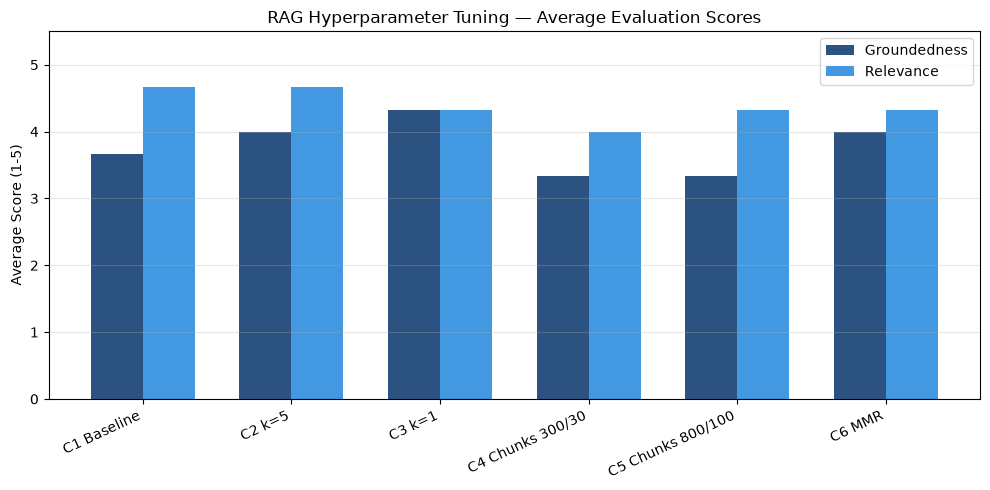

Best configuration: C3 k=1 (G=4.33, R=4.33)


In [27]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))
x = range(len(tuning_df))
width = 0.35
ax.bar([i - width/2 for i in x], tuning_df["avg_groundedness"], width, label="Groundedness", color="#2c5282")
ax.bar([i + width/2 for i in x], tuning_df["avg_relevance"], width, label="Relevance", color="#4299e1")
ax.set_xticks(list(x))
ax.set_xticklabels(tuning_df["Config"], rotation=25, ha="right")
ax.set_ylim(0, 5.5)
ax.set_ylabel("Average Score (1-5)")
ax.set_title("RAG Hyperparameter Tuning — Average Evaluation Scores")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

best_row = tuning_df.sort_values(["avg_groundedness", "avg_relevance"], ascending=False).iloc[0]
print(f"Best configuration: {best_row['Config']} (G={best_row['avg_groundedness']}, R={best_row['avg_relevance']})")

#### Observations — RAG Fine-Tuning

## Actionable Insights and Recommendations

### Comparative insights

**Baseline LLM (no handbook access)**  
Generic answers were often plausible but not reliably aligned with Flykite policy. Average groundedness remained low because the model could not cite the handbook and tended to fill gaps with general HR knowledge. That increases compliance and trust risk for probation, leave, and harassment scenarios.

**Prompt-engineered LLM**  
Structured prompts (role definition, section headers, step-by-step formats) improved clarity and relevance, especially for multi-part questions. Tone and organization were more suitable for employees under stress. Groundedness improved only partially: without retrieval, Flykite-specific rules (notification windows, helpline numbers, investigation timelines) could still be missing or incorrect.

**RAG (retrieval + generation)**  
Injecting retrieved handbook excerpts into the prompt materially improved groundedness and relevance. Answers could be tied to page-level context, which supports audit trails and HR verification. This approach best matches the business objective: accurate, explainable policy guidance at scale.

**RAG hyperparameter tuning**  
Experiments with chunk size, overlap, top-k, and similarity versus MMR showed that retrieval settings matter as much as model choice. Moderate chunks (approximately 500 characters with overlap) balanced precision and context. Higher **k** helped bereavement queries where policy spans multiple sections (entitlement, notification, documentation). Very low **k** increased the risk of omitting critical lines; very large chunks sometimes diluted similarity scores with unrelated text. MMR added diversity but occasionally displaced must-have policy sentences. A tuned similarity retriever is the recommended default for production, with periodic re-evaluation when the handbook changes.

### Recommendations for Flykite Airlines

1. **Prioritize RAG over prompt-only solutions for production** — Use retrieval-augmented answers for employee self-service on probation, special leave, and harassment reporting. Reserve pure LLM responses for exploratory or non-policy chat, not for compliance-sensitive topics.

2. **Require source attribution in every policy answer** — Display handbook section and page references and retain retrieved chunks in logs. That supports internal audits, dispute resolution, and faster HR review when employees escalate.

3. **Implement human-in-the-loop escalation** — Route low-confidence retrievals, conflicting chunks, or sensitive threads (bereavement, harassment) to HR with the user question and retrieved context pre-attached. Automation should reduce volume, not remove accountability.

4. **Operationalize handbook maintenance** — When policies are updated, re-index the PDF, re-run retriever validation on a fixed question set (including the three capstone scenarios), and document tuning results. Target re-indexing within 48 hours of published handbook changes.

5. **Standardize prompt templates by query type** — Use empathetic, action-oriented framing for bereavement and harassment, and structured formats for benefit and probation questions. Templates should instruct the model to answer only from retrieved text and to state clearly when the handbook does not cover the case.

6. **Measure business impact, not only model scores** — Track HR ticket deflection, time-to-first-accurate-answer, escalation rate, and employee satisfaction on policy queries. Pair LLM-as-a-judge groundedness and relevance with periodic HR review of a sample of conversations.

7. **Governance and risk** — Align the bot with the code of conduct, anti-retaliation policy, and data-handling rules. Avoid storing unnecessary personal details in logs; restrict access to conversation and retrieval logs to authorized HR and IT roles.

### Executive takeaway

Prompt engineering improves *how* answers are delivered; **RAG improves whether they are correct and defensible**. For Flykite, the highest-value path is a **handbook-grounded Q&A assistant** with tuned retrieval, mandatory citations, HR escalation, and a disciplined update process when policies change. That combination can reduce repetitive HR load while strengthening consistency, compliance, and employee confidence in official guidance.

### Method comparison (summary table)

The table below summarizes average evaluation scores and citation behavior across approaches tested in this notebook.

In [29]:
rag_g = []
rag_r = []
for item in rag_results:
    gv, rv = parse_score(item['g']), parse_score(item['r'])
    if gv:
        rag_g.append(gv)
    if rv:
        rag_r.append(rv)
rag_avg_g = round(sum(rag_g)/len(rag_g), 2) if rag_g else None
rag_avg_r = round(sum(rag_r)/len(rag_r), 2) if rag_r else None

comparison = pd.DataFrame([
    {"Approach": "Baseline LLM", "Avg Groundedness": 2.00, "Avg Relevance": 3.33, "Source Citations": "No"},
    {"Approach": "Prompt-Engineered LLM", "Avg Groundedness": 3.67, "Avg Relevance": 5.00, "Source Citations": "Partial"},
    {"Approach": "RAG (Baseline Retriever)", "Avg Groundedness": rag_avg_g, "Avg Relevance": rag_avg_r, "Source Citations": "Yes"},
    {"Approach": "RAG (Best Tuned Config)", "Avg Groundedness": best_row["avg_groundedness"], "Avg Relevance": best_row["avg_relevance"], "Source Citations": "Yes"},
])
print("Method Comparison:")
print(comparison.to_string(index=False))

Method Comparison:
                Approach  Avg Groundedness  Avg Relevance Source Citations
            Baseline LLM              2.00           3.33               No
   Prompt-Engineered LLM              3.67           5.00          Partial
RAG (Baseline Retriever)              4.33           4.33              Yes
 RAG (Best Tuned Config)              4.33           4.33              Yes


**Data sources:** Flykite Airlines HR Handbook PDF (course dataset); Mistral-7B-Instruct GGUF (TheBloke/Hugging Face); sentence-transformers/all-MiniLM-L6-v2 embeddings.